In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date

In [2]:
reports = pd.read_parquet('../data/processed/reports.parquet')

reports.info()

assert reports['report_id'].is_unique

<class 'pandas.DataFrame'>
RangeIndex: 532 entries, 0 to 531
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   enr                     532 non-null    str           
 1   report_id               532 non-null    str           
 2   initial_report_id       376 non-null    str           
 3   report_type             532 non-null    str           
 4   start_date              532 non-null    datetime64[us]
 5   end_date                532 non-null    datetime64[us]
 6   last_report_date        532 non-null    datetime64[us]
 7   reason_type             532 non-null    str           
 8   drug_name               532 non-null    str           
 9   atc_code                521 non-null    str           
 10  active_ingredients      532 non-null    str           
 11  hospital_relevant       532 non-null    bool          
 12  licensee                532 non-null    str           
 13  r

In [3]:
def plot_counts(column, title, filename):

    fig, ax = plt.subplots(figsize=(10,6))

    group_counts = reports[column].value_counts()

    ax.barh(group_counts.index, width=group_counts.values)

    ax.invert_yaxis()

    ax.set_title(title)

    n_missing = reports[column].isna().sum()
    if n_missing > 0:
        ax.set_xlabel(f"Number of shortage reports ({n_missing} without a value)")
    else:
        ax.set_xlabel("Number of shortage reports")

    plt.tight_layout()
    fig.savefig(filename, bbox_inches='tight')
    plt.show()

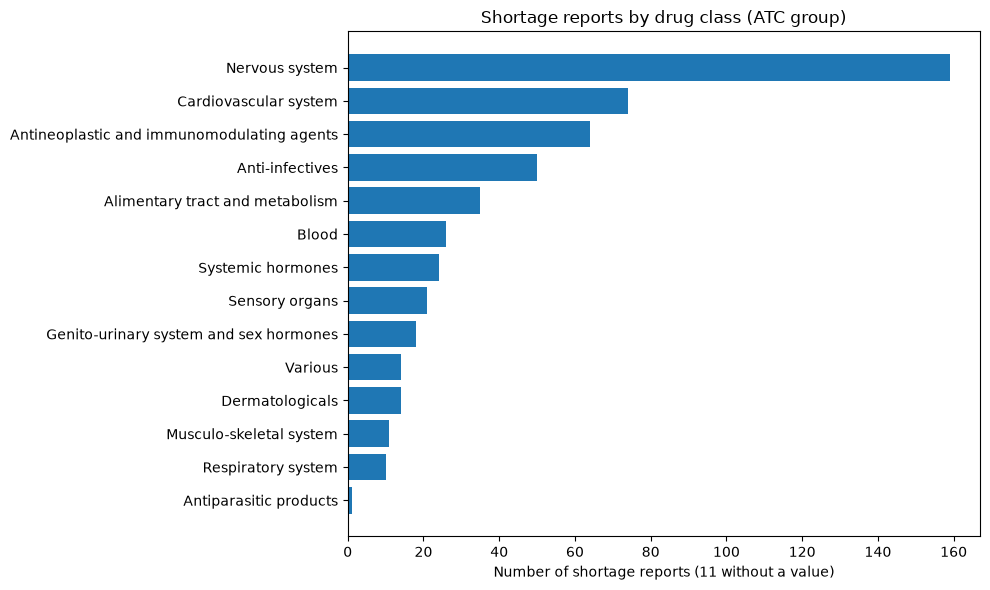

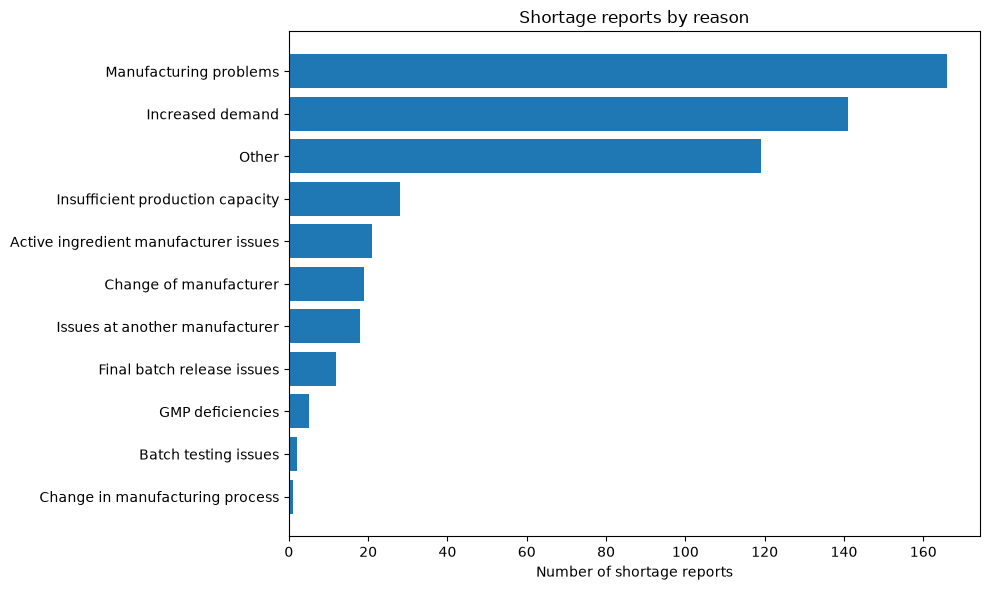

In [4]:
plot_counts('atc_group',
            'Shortage reports by drug class (ATC group)',
            '../reports/figures/shortages_by_atc_group.png' 
            )

plot_counts('reason',
            'Shortage reports by reason',
            '../reports/figures/shortages_by_reason.png' 
            )

In [5]:
reports['duration_days'] = (reports['end_date'] - reports['start_date']).dt.days

display(reports['duration_days'].describe())

reports['expired'] = reports['end_date'].dt.date < date.today()
reports['expires_on_2030'] = reports['end_date'].dt.date == date(2030,1,1)

reports[['expired', 'expires_on_2030']].apply(pd.Series.value_counts)

count     532.000000
mean      482.201128
std       484.386827
min        13.000000
25%       141.500000
50%       334.500000
75%       696.750000
max      3105.000000
Name: duration_days, dtype: float64

,expired,expires_on_2030
False,518,530
True,14,2


In [6]:
reason_type_share = reports['reason_type'].value_counts(normalize=True)
display(reason_type_share)

reason_type
other                 0.56391
production_problem    0.43609
Name: proportion, dtype: float64

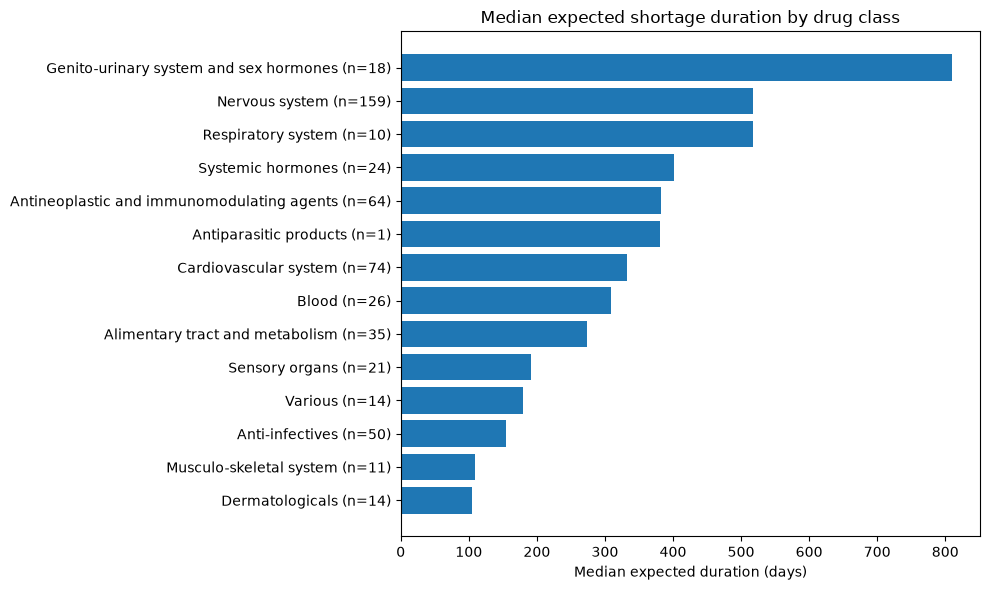

In [7]:
fig, ax = plt.subplots(figsize=(10,6))
days_per_atc = reports[['atc_group', 'duration_days']].groupby('atc_group').median().sort_values('duration_days',ascending=False)

counts_per_group = reports['atc_group'].value_counts()
Y = []
for group in days_per_atc.index:
    counts = counts_per_group[group]
    y = f"{group} (n={counts})"
    Y.append(y)
ax.barh(y=Y, width=days_per_atc['duration_days'])

ax.invert_yaxis()
ax.set_title("Median expected shortage duration by drug class")
ax.set_xlabel("Median expected duration (days)")
plt.tight_layout()
fig.savefig('../reports/figures/duration_by_atc_group.png', bbox_inches='tight')
plt.show()

In [8]:
print(f'{reports['hospital_relevant'].mean():.0%}')
for k, v in reports['classification'].value_counts(normalize=True).items():
    print(f'{k}: {v:.0%}')

31%
neither: 46%
supply_relevant: 29%
supply_critical: 26%


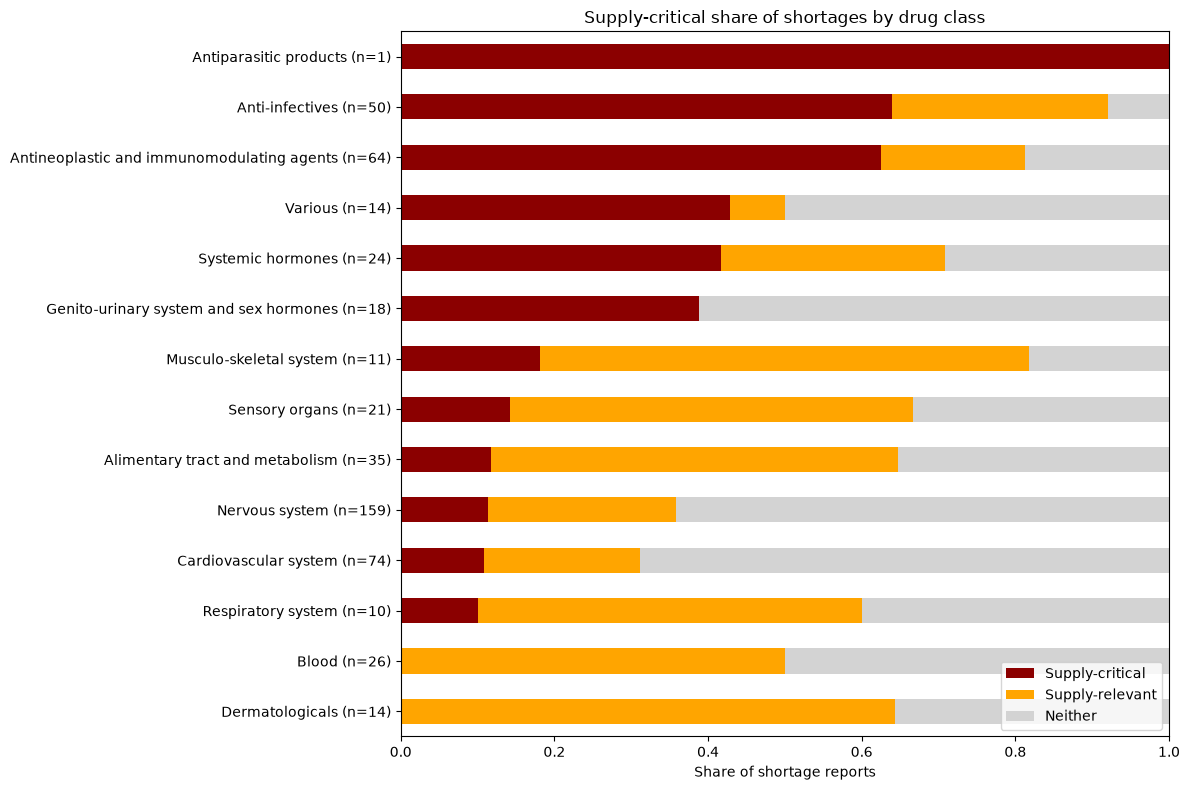

In [9]:
fig, ax = plt.subplots(figsize=(12,8))
shortage_per_class = pd.crosstab(reports['atc_group'], reports['classification'], normalize='index')

shortage_per_class_sorted = shortage_per_class.sort_values(by='supply_critical', ascending=False)[['supply_critical', 'supply_relevant', 'neither']]

shortage_per_class_sorted.plot(kind='barh', stacked=True, ax=ax, color=['darkred', 'orange','lightgrey'])
ax.invert_yaxis()

labels = []
for i in shortage_per_class_sorted.index:
    counts = counts_per_group[i]
    y = f"{i} (n={counts})" 
    labels.append(y)

ax.set_yticklabels(labels)
ax.legend(loc='lower right', labels=['Supply-critical', 'Supply-relevant', 'Neither'])
ax.set_ylabel('')
ax.set_title('Supply-critical share of shortages by drug class')
ax.set_xlabel('Share of shortage reports')

plt.tight_layout()
fig.savefig('../reports/figures/criticality_by_atc_group.png', bbox_inches='tight')
plt.show()